In [20]:

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("Libraries imported successfully!")


Libraries imported successfully!


In [22]:

from google.colab import files
import io

uploaded = files.upload()


Saving spam_sms.csv to spam_sms (1).csv


In [23]:

import io
import zipfile

uploaded = files.upload()

filename = next(iter(uploaded))

if filename.lower().endswith(".zip"):
    with zipfile.ZipFile(io.BytesIO(uploaded[filename])) as z:
        csv_names = [
            n for n in z.namelist()
            if n.lower().endswith(".csv") and not n.endswith("/")
        ]
        if not csv_names:
            raise ValueError("No CSV file found inside the ZIP.")
        print("CSV files:", csv_names)
        csv_name = csv_names[0]
        df = pd.read_csv(
            z.open(csv_name),
            encoding="utf-8",
            encoding_errors="replace"
        )
elif filename.lower().endswith(".csv"):
    df = pd.read_csv(
        io.BytesIO(uploaded[filename]),
        encoding="utf-8",
        encoding_errors="replace"
    )
else:
    raise ValueError("Please upload a CSV file or a ZIP containing a CSV.")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


Saving spam_sms.csv to spam_sms (2).csv
Dataset loaded successfully!
Shape: (5572, 2)
Columns: ['v1', 'v2']


,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [24]:

columns = {str(c).strip().lower(): c for c in df.columns}

label_candidates = [
    "label", "v1", "category", "class", "spam", "target"
]
text_candidates = [
    "message", "v2", "text", "sms", "message_body"
]

label_col = next(
    (columns[c] for c in label_candidates if c in columns), None
)
text_col = next(
    (columns[c] for c in text_candidates if c in columns), None
)

if label_col is None or text_col is None:
    raise ValueError(
        "Could not identify columns. Check df.head() and set "
        "label_col and text_col manually."
    )

data = df[[label_col, text_col]].copy()
data.columns = ["label", "message"]

data = data.dropna(subset=["label", "message"])
data["label"] = data["label"].astype(str).str.strip().str.lower()
data["message"] = data["message"].astype(str).str.strip()

data["label"] = data["label"].replace({
    "0": "ham",
    "1": "spam"
})

data = data[data["label"].isin(["ham", "spam"])]
data = data[data["message"] != ""]
data = data.drop_duplicates(subset=["message"])

if data["label"].nunique() != 2:
    raise ValueError(
        "Both ham and spam labels are required. "
        "Inspect the label values in your dataset."
    )

if len(data) > 2000:
    data = data.groupby("label", group_keys=False).apply(
        lambda group: group.sample(
            n=max(
                1,
                round(2000 * len(group) / len(data))
            ),
            random_state=42
        )
    ).reset_index(drop=True)

    if len(data) > 2000:
        data = data.sample(n=2000, random_state=42)

data = data.sample(frac=1, random_state=42).reset_index(drop=True)

print("Total messages:", len(data))
print("\nClass distribution:")
print(data["label"].value_counts())
display(data.head())


Total messages: 2000

Class distribution:
label
ham     1751
spam     249
Name: count, dtype: int64


/tmp/ipykernel_1287/3015865286.py:46: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  data = data.groupby("label", group_keys=False).apply(


,label,message
0,spam,Natalja (25/F) is inviting you to be her frien...
1,ham,I'm ok. Will do my part tomorrow
2,ham,Waaaat?? Lololo ok next time then!
3,ham,what is your account number?
4,ham,No b4 Thursday


In [25]:

def clean_text(message):
    message = message.lower()
    message = re.sub(r"http\S+|www\.\S+", " URL ", message)
    message = re.sub(r"[^a-z0-9\s]", " ", message)
    message = re.sub(r"\s+", " ", message).strip()
    return message

data["message"] = data["message"].apply(clean_text)
data = data[data["message"] != ""].reset_index(drop=True)

print("Text preprocessing completed!")
display(data.head())


Text preprocessing completed!


,label,message
0,spam,natalja 25 f is inviting you to be her friend ...
1,ham,i m ok will do my part tomorrow
2,ham,waaaat lololo ok next time then
3,ham,what is your account number
4,ham,no b4 thursday


In [26]:

X = data["message"].astype(str).to_numpy()
y = data["label"].map({"ham": 0, "spam": 1}).to_numpy()

valid = pd.notna(y) & (X != "")
X = X[valid]
y = y[valid].astype(int)

print("Total messages:", len(X))
print("Label counts (ham=0, spam=1):")
print(pd.Series(y).value_counts().sort_index())

if len(np.unique(y)) != 2:
    raise ValueError("Both ham and spam must be present.")

if np.min(np.bincount(y)) < 2:
    raise ValueError("Each class needs at least 2 messages.")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))


Total messages: 2000
Label counts (ham=0, spam=1):
0    1751
1     249
Name: count, dtype: int64
Training messages: 1600
Testing messages: 400


In [27]:

vocab_size = 5000
max_len = 100

tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

train_seq = tokenizer.texts_to_sequences(X_train)
test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    train_seq,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    test_seq,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)
print("Tokenization and padding completed!")


Training shape: (1600, 100)
Testing shape: (400, 100)
Tokenization and padding completed!


In [28]:

tf.keras.utils.set_random_seed(42)

model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=32),
    LSTM(32),
    Dropout(0.3),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

print("Training completed!")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.8555 - loss: 0.4740 - val_accuracy: 0.8656 - val_loss: 0.4082
Epoch 2/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.8781 - loss: 0.3787 - val_accuracy: 0.8656 - val_loss: 0.3958
Epoch 3/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.8781 - loss: 0.3747 - val_accuracy: 0.8656 - val_loss: 0.3955
Epoch 4/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - accuracy: 0.8781 - loss: 0.3793 - val_accuracy: 0.8656 - val_loss: 0.3954
Epoch 5/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.8781 - loss: 0.3803 - val_accuracy: 0.8656 - val_loss: 0.3950
Epoch 6/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.8781 - loss: 0.3730 - val_accuracy: 0.8656 - val_loss: 0.3954
Epoch 7/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.8781 - loss: 0.3784 - val_accuracy: 0.8656 - val_loss: 0.3949
Epoch 8/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.8781 - loss: 0.3769 - val_accuracy: 0.8656 - v

Accuracy : 0.875
Precision: 0.0
Recall   : 0.0
F1-score : 0.0

Classification Report:
              precision    recall  f1-score   support

         Ham       0.88      1.00      0.93       350
        Spam       0.00      0.00      0.00        50

    accuracy                           0.88       400
   macro avg       0.44      0.50      0.47       400
weighted avg       0.77      0.88      0.82       400



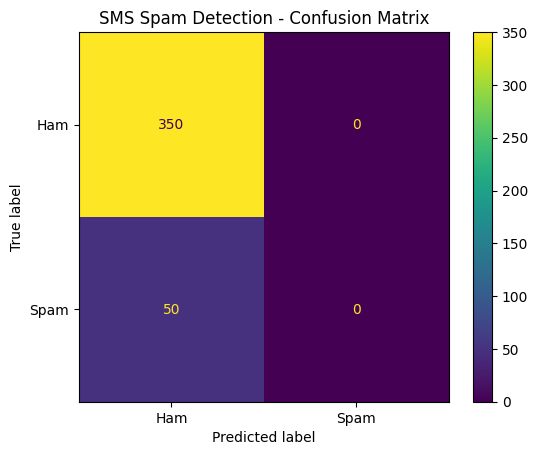

In [29]:

probabilities = model.predict(X_test_pad, verbose=0).ravel()
y_pred = (probabilities >= 0.5).astype(int)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(
    y_test, y_pred, zero_division=0
), 4))
print("Recall   :", round(recall_score(
    y_test, y_pred, zero_division=0
), 4))
print("F1-score :", round(f1_score(
    y_test, y_pred, zero_division=0
), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Ham", "Spam"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot(values_format="d")
plt.title("SMS Spam Detection - Confusion Matrix")
plt.show()


In [30]:

def predict_sms(message):
    cleaned = clean_text(message)

    sequence = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(
        sequence,
        maxlen=max_len,
        padding="post",
        truncating="post"
    )

    probability = float(
        model.predict(padded, verbose=0)[0][0]
    )

    prediction = (
        "SPAM" if probability >= 0.5 else "HAM (NOT SPAM)"
    )

    print("Message:", message)
    print("Prediction:", prediction)
    print("Spam probability:", round(probability * 100, 2), "%")
    print("-" * 40)

predict_sms(
    "Congratulations! You won a free prize. Click here to claim."
)
predict_sms("Hey, are we meeting at college tomorrow?")
predict_sms("URGENT! You have won a cash reward. Call now.")
predict_sms("Please bring your notebook to class.")

model.save("/content/sms_spam_lstm.keras")

with open("/content/tokenizer.json", "w", encoding="utf-8") as f:
    f.write(tokenizer.to_json())

print("Model and tokenizer saved successfully!")


Message: Congratulations! You won a free prize. Click here to claim.
Prediction: HAM (NOT SPAM)
Spam probability: 13.3 %
----------------------------------------
Message: Hey, are we meeting at college tomorrow?
Prediction: HAM (NOT SPAM)
Spam probability: 13.3 %
----------------------------------------
Message: URGENT! You have won a cash reward. Call now.
Prediction: HAM (NOT SPAM)
Spam probability: 13.3 %
----------------------------------------
Message: Please bring your notebook to class.
Prediction: HAM (NOT SPAM)
Spam probability: 13.3 %
----------------------------------------
Model and tokenizer saved successfully!
